# Customer Lifetime Value Prediction for E-Commerce
Regression models (Linear Regression, Decision Tree) to predict each customer's future spend.

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("figures", exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=130); plt.show()

## 1. Load data
Uses the UCI *Online Retail II* file if it is placed in `data/`; otherwise falls back to a synthetic log with the identical schema (the sandbox this was built in could not download the UCI file).

In [2]:
# 1. LOAD (real UCI file if present, else synthetic)
real = [p for p in ["data/online_retail_II.xlsx", "data/online_retail_II.csv"] if os.path.exists(p)]
if real:
    df = pd.read_excel(real[0]) if real[0].endswith("xlsx") else pd.read_csv(real[0], parse_dates=["InvoiceDate"])
    SOURCE = "UCI Online Retail II"
else:
    df = pd.read_csv("data/online_retail_synthetic.csv", parse_dates=["InvoiceDate"])
    SOURCE = "synthetic (same schema as Online Retail II)"
print("Data source:", SOURCE, "| raw rows:", len(df))


Data source: synthetic (same schema as Online Retail II) | raw rows: 99452


## 2. Cleaning
Removed guest checkouts (no Customer ID), cancelled invoices (prefix `C`), non-positive quantities/prices and duplicates; created `Revenue = Quantity × Price`.

In [3]:
# 2. CLEAN
n0 = len(df)
df = df.dropna(subset=["Customer ID"])
df = df[~df["Invoice"].astype(str).str.startswith("C")]
df = df[(df.Quantity > 0) & (df.Price > 0)].drop_duplicates()
df["Revenue"] = df.Quantity * df.Price
print(f"Rows kept after cleaning: {len(df):,} of {n0:,}")


Rows kept after cleaning: 95,006 of 99,452


## 3. Time-based split (avoids target leakage)
Features come only from the **feature window**; the target is each customer's total spend in the **following ~3 months**. Customers with no purchases in that window have LTV = 0 and are kept.

In [4]:
# 3. TIME SPLIT (feature window -> target window)
d_min, d_max = df.InvoiceDate.min(), df.InvoiceDate.max()
cutoff = d_max - pd.Timedelta(days=92)
feat, targ = df[df.InvoiceDate < cutoff], df[df.InvoiceDate >= cutoff]
print("Feature window:", d_min.date(), "->", cutoff.date(), "| Target window:", cutoff.date(), "->", d_max.date())


Feature window: 2010-12-01 -> 2011-09-07 | Target window: 2011-09-07 -> 2011-12-08


## 4. Feature engineering
RFM (Recency, Frequency, Monetary) plus AvgOrderValue, Tenure, UniqueProducts, AvgItemsPerOrder, PurchaseRate, Last90dOrders and a UK flag (the dataset has no demographics, so Country is the only demographic-style feature). Skewed features and the target are capped at the 99th percentile.

In [5]:
# 4. FEATURES
g = feat.groupby("Customer ID")
X = pd.DataFrame({
    "Recency": (cutoff - g.InvoiceDate.max()).dt.days,
    "Frequency": g.Invoice.nunique(),
    "Monetary": g.Revenue.sum(),
    "AvgOrderValue": g.Revenue.sum() / g.Invoice.nunique(),
    "Tenure": (cutoff - g.InvoiceDate.min()).dt.days,
    "UniqueProducts": g.StockCode.nunique(),
    "AvgItemsPerOrder": g.Quantity.sum() / g.Invoice.nunique(),
    "IsUK": (g.Country.first() == "United Kingdom").astype(int),
})
X["PurchaseRate"] = X.Frequency / (X.Tenure + 1)
X["Last90dOrders"] = feat[feat.InvoiceDate >= cutoff - pd.Timedelta(days=90)].groupby("Customer ID").Invoice.nunique().reindex(X.index).fillna(0)
y = targ.groupby("Customer ID").Revenue.sum().reindex(X.index).fillna(0).rename("FutureLTV")
print("Customers:", len(X), "| share with zero future spend: %.1f%%" % (100 * (y == 0).mean()))
print(X.isna().sum().sum(), "missing feature values")

# outlier capping (99th percentile)
caps = {c: X[c].quantile(0.99) for c in ["Monetary", "AvgOrderValue", "AvgItemsPerOrder", "UniqueProducts"]}
for c, v in caps.items():
    X[c] = X[c].clip(upper=v)
cap_y = y.quantile(0.99); y = y.clip(upper=cap_y)


Customers: 4370 | share with zero future spend: 59.4%
0 missing feature values


## 5. Exploratory visualisation

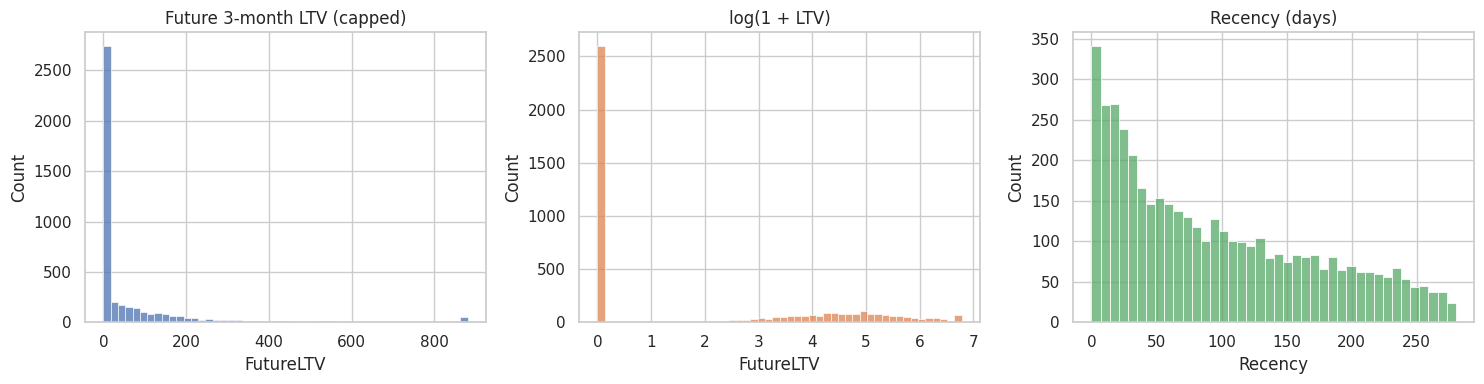

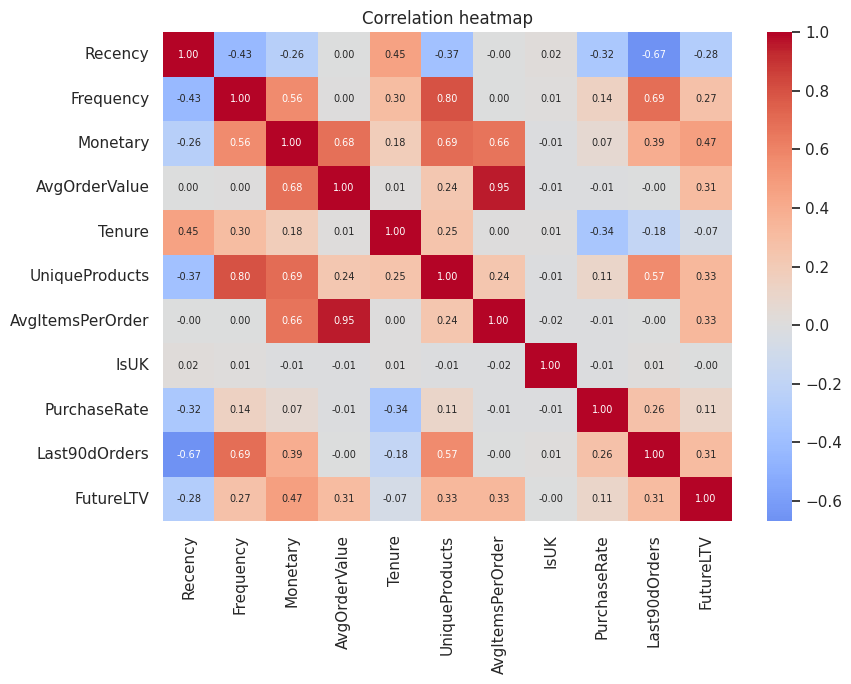

In [6]:
# 5. EDA PLOTS
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(y, bins=50, ax=ax[0]); ax[0].set_title("Future 3-month LTV (capped)")
sns.histplot(np.log1p(y), bins=50, ax=ax[1], color="C1"); ax[1].set_title("log(1 + LTV)")
sns.histplot(X.Recency, bins=40, ax=ax[2], color="C2"); ax[2].set_title("Recency (days)")
savefig("01_distributions")

plt.figure(figsize=(9, 7))
sns.heatmap(pd.concat([X, y], axis=1).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation heatmap"); savefig("02_correlation")


## 6. Train/test split, customer segmentation, scaling
80/20 split. K-Means (k=4) on log-RFM is fitted on the training set only and added as one-hot features. Scaling is applied for Linear Regression only.

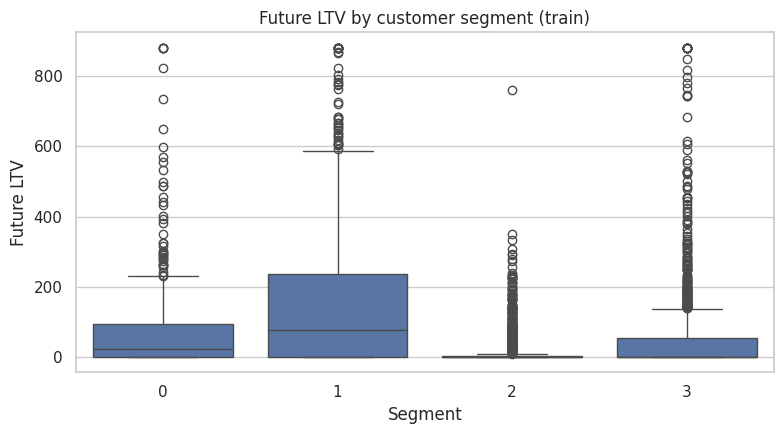

         Recency  Frequency  Monetary  Count  AvgFutureLTV
Segment                                                   
0           12.4        2.5     141.5    456          77.7
1           30.4        6.8     711.4    717         167.0
2          149.3        1.2      55.8   1152          19.6
3          112.2        2.7     286.4   1171          58.8


In [7]:
# 6. SPLIT, SEGMENT, SCALE
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
rfm = ["Recency", "Frequency", "Monetary"]
seg_sc = StandardScaler().fit(np.log1p(Xtr[rfm]))
km = KMeans(4, random_state=42, n_init=10).fit(seg_sc.transform(np.log1p(Xtr[rfm])))
Xtr = Xtr.assign(Segment=km.labels_)
Xte = Xte.assign(Segment=km.predict(seg_sc.transform(np.log1p(Xte[rfm]))))
Xtr_d = pd.get_dummies(Xtr, columns=["Segment"], prefix="Seg", dtype=int)
Xte_d = pd.get_dummies(Xte, columns=["Segment"], prefix="Seg", dtype=int).reindex(columns=Xtr_d.columns, fill_value=0)

plt.figure(figsize=(8, 4.5))
sns.boxplot(x=Xtr.Segment, y=ytr.values); plt.title("Future LTV by customer segment (train)"); plt.xlabel("Segment"); plt.ylabel("Future LTV")
savefig("03_segments")
print(Xtr.groupby("Segment")[rfm].mean().round(1).assign(Count=Xtr.Segment.value_counts().sort_index(), AvgFutureLTV=ytr.groupby(Xtr.Segment).mean().round(1)))

sc = StandardScaler().fit(Xtr_d)


## 7. Models
Linear Regression vs Decision Tree (tuned with 5-fold GridSearchCV over `max_depth` and `min_samples_leaf`).

In [8]:
# 7. MODELS
lr = LinearRegression().fit(sc.transform(Xtr_d), ytr)
gs = GridSearchCV(DecisionTreeRegressor(random_state=42),
                  {"max_depth": [3, 4, 5, 6, 8], "min_samples_leaf": [5, 10, 20, 50]},
                  cv=5, scoring="r2").fit(Xtr_d, ytr)
dt = gs.best_estimator_
print("Best tree params:", gs.best_params_, "| CV R2: %.3f" % gs.best_score_)

res = {}
for name, m, Xt_tr, Xt_te in [("Linear Regression", lr, sc.transform(Xtr_d), sc.transform(Xte_d)),
                              ("Decision Tree", dt, Xtr_d, Xte_d)]:
    p = m.predict(Xt_te)
    res[name] = dict(pred=p, R2=r2_score(yte, p), MAE=mean_absolute_error(yte, p),
                     RMSE=np.sqrt(mean_squared_error(yte, p)),
                     Train_R2=r2_score(ytr, m.predict(Xt_tr)))
results = pd.DataFrame({k: {m: v[m] for m in ["R2", "MAE", "RMSE", "Train_R2"]} for k, v in res.items()}).T.round(3)
print(results)
print("Baseline (predict train mean): MAE = %.1f" % mean_absolute_error(yte, np.full(len(yte), ytr.mean())))


Best tree params: {'max_depth': 5, 'min_samples_leaf': 50} | CV R2: 0.238
                      R2     MAE     RMSE  Train_R2
Linear Regression  0.246  80.769  134.319     0.270
Decision Tree      0.225  78.521  136.211     0.326
Baseline (predict train mean): MAE = 95.0


## 8. Evaluation plots

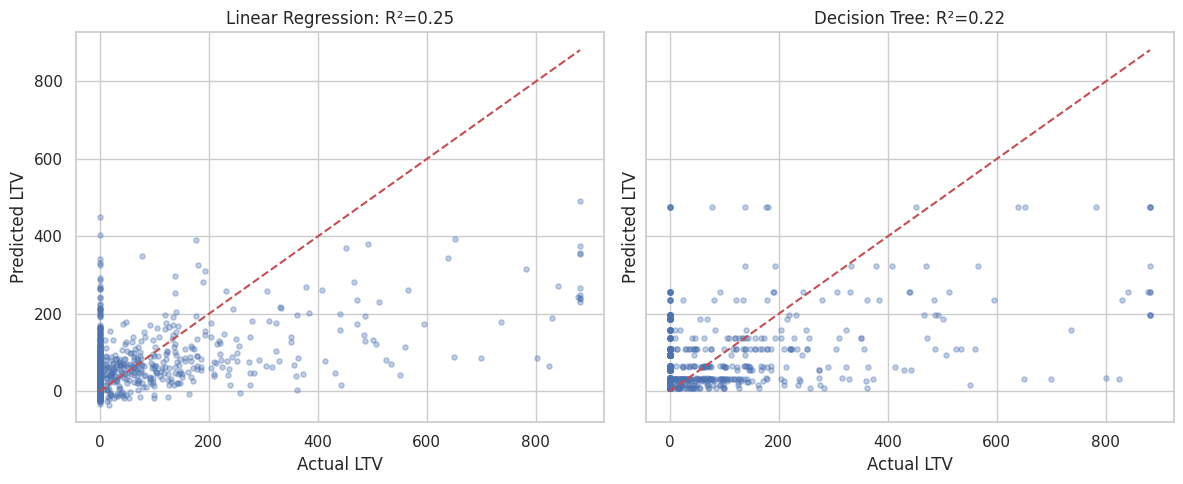

Best model on test R²: Linear Regression


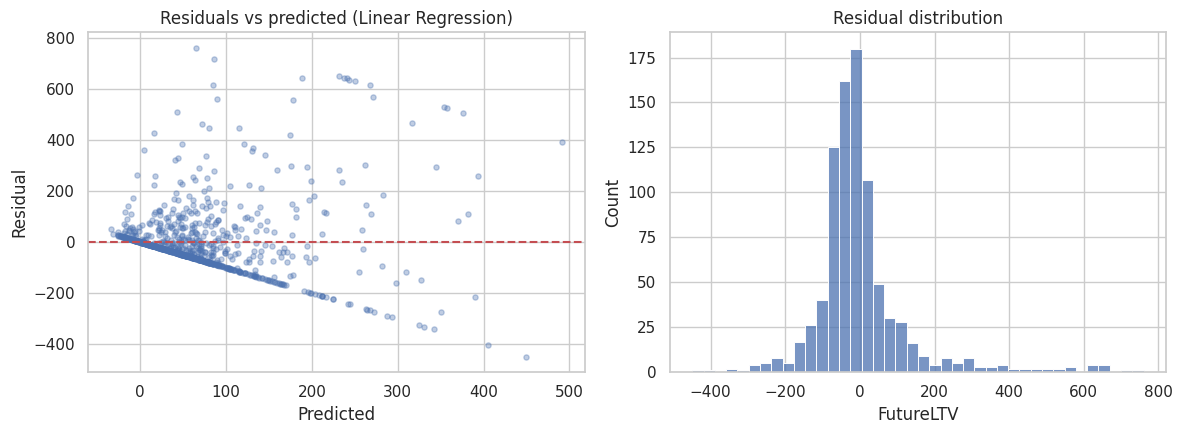

In [9]:
# 8. EVALUATION PLOTS
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for a, (n, v) in zip(ax, res.items()):
    a.scatter(yte, v["pred"], alpha=.35, s=14); lim = [0, max(yte.max(), v["pred"].max())]
    a.plot(lim, lim, "r--"); a.set_title(f"{n}: R²={v['R2']:.2f}"); a.set_xlabel("Actual LTV"); a.set_ylabel("Predicted LTV")
savefig("04_pred_vs_actual")

best = max(res, key=lambda k: res[k]["R2"]); print("Best model on test R²:", best)
resid = yte - res[best]["pred"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(res[best]["pred"], resid, alpha=.35, s=14); ax[0].axhline(0, color="r", ls="--"); ax[0].set_title(f"Residuals vs predicted ({best})"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Residual")
sns.histplot(resid, bins=40, ax=ax[1]); ax[1].set_title("Residual distribution")
savefig("05_residuals")


## 9. Interpretation

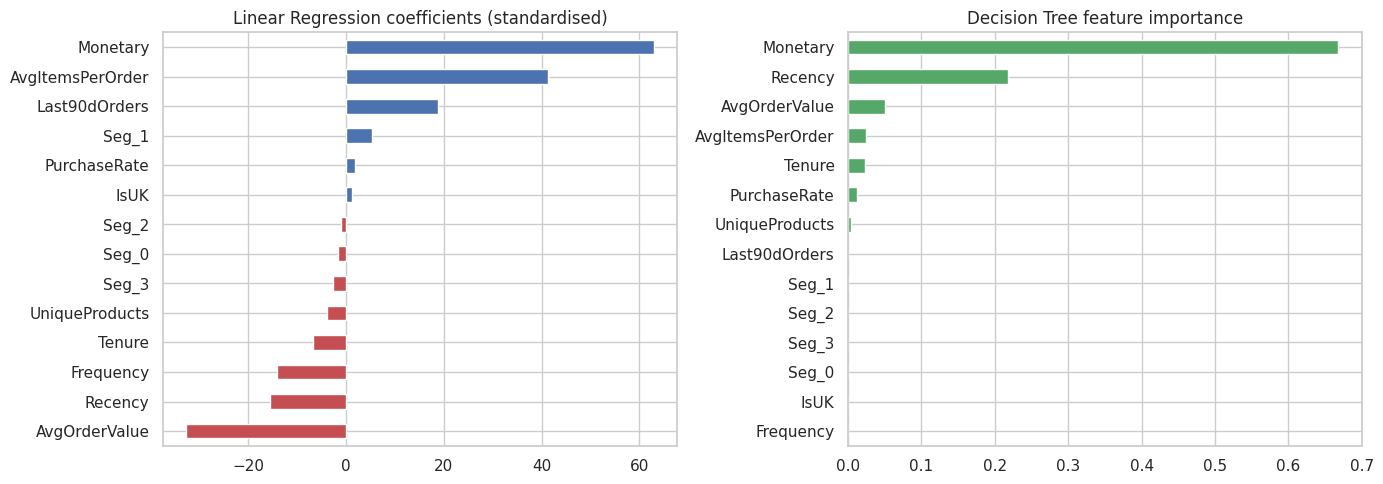


Top coefficients:
 Monetary            62.93
AvgItemsPerOrder    41.31
AvgOrderValue      -32.69
Last90dOrders       18.81
Recency            -15.49
dtype: float64

Top tree features:
 Monetary            0.667
Recency             0.218
AvgOrderValue       0.050
AvgItemsPerOrder    0.024
Tenure              0.023
dtype: float64


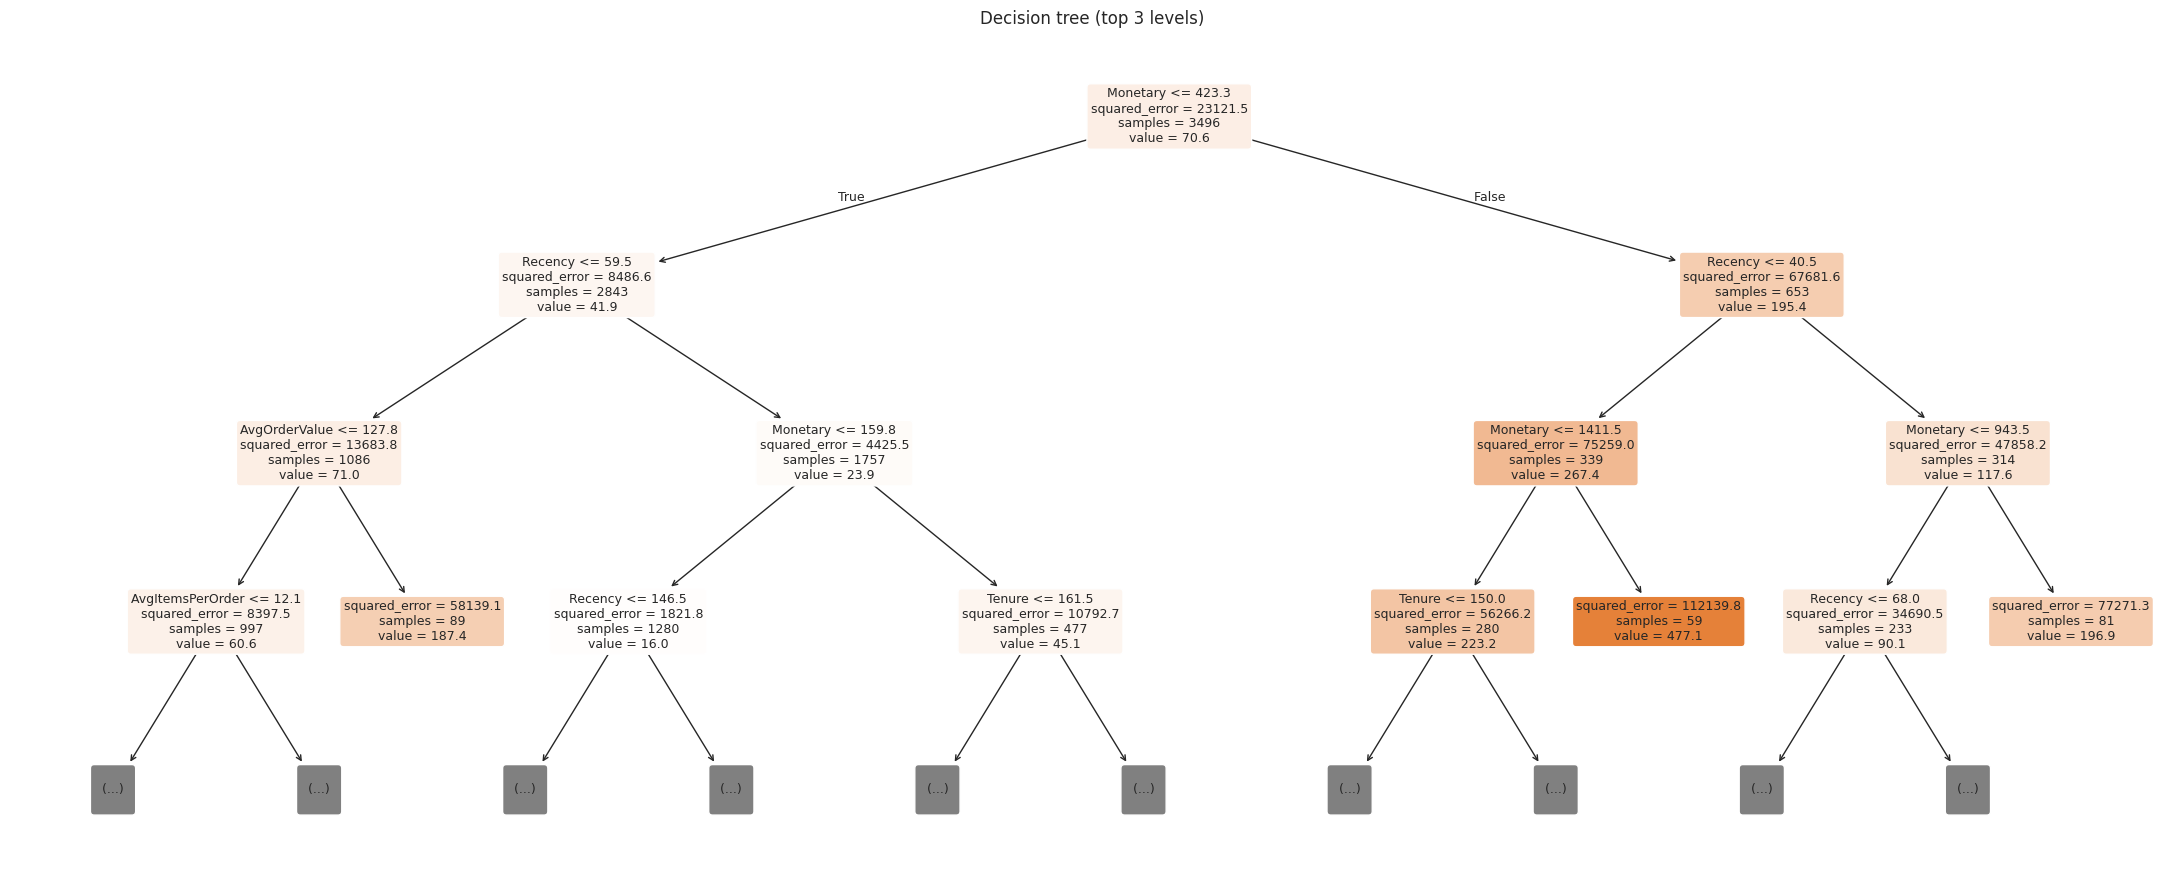

In [10]:
# 9. INTERPRETATION
coef = pd.Series(lr.coef_, index=Xtr_d.columns).sort_values()
imp = pd.Series(dt.feature_importances_, index=Xtr_d.columns).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
coef.plot.barh(ax=ax[0], color=np.where(coef < 0, "C3", "C0")); ax[0].set_title("Linear Regression coefficients (standardised)")
imp.plot.barh(ax=ax[1], color="C2"); ax[1].set_title("Decision Tree feature importance")
savefig("06_coef_importance")
print("\nTop coefficients:\n", coef.sort_values(key=abs, ascending=False).head(5).round(2))
print("\nTop tree features:\n", imp.sort_values(ascending=False).head(5).round(3))

plt.figure(figsize=(22, 9))
plot_tree(dt, feature_names=Xtr_d.columns, filled=True, max_depth=3, fontsize=9, rounded=True, precision=1)
plt.title("Decision tree (top 3 levels)"); savefig("07_tree")


## 10. Results and business insights

| Model | Test R² | MAE | RMSE |
|---|---|---|---|
| Linear Regression | 0.246 | 80.8 | 134.3 |
| Decision Tree (depth 5, min leaf 50) | 0.225 | 78.5 | 136.2 |
| Baseline (predict mean) | – | 95.0 | – |

* Both models beat the mean baseline (MAE falls from 95.0 to about 79–81). Linear Regression has the higher R²; the tree has a slightly lower MAE. Neither is clearly better, which is expected because future spend is noisy and about 59% of customers spend nothing in the target window.
* **Monetary value and Recency drive predictions.** Monetary has the largest Linear Regression coefficient and 67% of the tree's importance; Recency (negative effect) has 22%. Customers who spent a lot historically and bought recently are predicted to be worth the most.
* **Tree splits.** The root split is Monetary ≤ 423 (mean future spend 42 vs 195 either side). Among big spenders, those who also bought within about 40 days and have Monetary above about 1,411 are predicted at roughly 477 over the next 3 months, the highest-value leaf.
* **Segmentation confirms it.** The segment with high frequency and moderate recency (about 7 orders, 30 days since last purchase) has an average future spend of about 167, versus about 20 for the long-lapsed, one-order segment.
* **Actions:** (1) protect the high-value, recently active segment with loyalty rewards; (2) trigger win-back offers for customers whose recency is drifting past about 100 days; (3) nudge one-order customers toward a second purchase, since frequency is the lever that moves them to higher segments.
* **Caution:** Monetary and AvgOrderValue are correlated (Monetary = Frequency × AOV), so individual linear coefficients, such as the negative AvgOrderValue one, should be read together rather than alone.

## 11. Limitations
Synthetic data was used here; rerun on the real Online Retail II file for final numbers. There are no true demographics, the horizon is only 3 months, and outliers were capped. Future work: Random Forest/Gradient Boosting and probabilistic BG/NBD + Gamma-Gamma models.
